In [104]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [105]:
np.random.seed(42)
import numpy as np

# X = GPA (Shape: 10 rows, 1 column)
x = np.array([8.97, 9.36, 7.78, 8.57, 6.26, 7.45, 6.59, 9.62, 7.82, 8.01])

# y = Package in LPA (Shape: 10 elements)
y = np.array([19.24, 18.02, 12.31, 14.92,  7.68, 
              10.98,  8.15, 21.43, 14.22, 13.57])

x,y

(array([8.97, 9.36, 7.78, 8.57, 6.26, 7.45, 6.59, 9.62, 7.82, 8.01]),
 array([19.24, 18.02, 12.31, 14.92,  7.68, 10.98,  8.15, 21.43, 14.22,
        13.57]))

In [106]:
nume=sum((x-x.mean())*(y-y.mean()))
den=sum((x-x.mean())**2)

m=nume/den
b=y.mean()-m*x.mean()
m,b

(3.9857199509730306, -18.00514556567608)

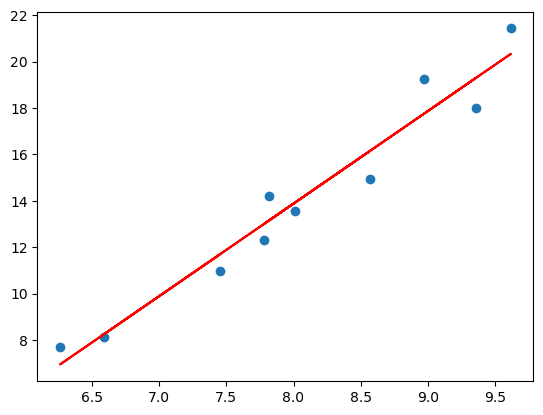

In [107]:
plt.scatter(x,y)
plt.plot(x,m*x+b,color='r')

In [108]:
from sklearn.linear_model import LinearRegression
model= LinearRegression()
model.fit(x.reshape(-1,1),y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[3.99]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-18.01
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.33]


In [109]:
model.coef_,model.intercept_

(array([3.98571995]), -18.005145565676095)

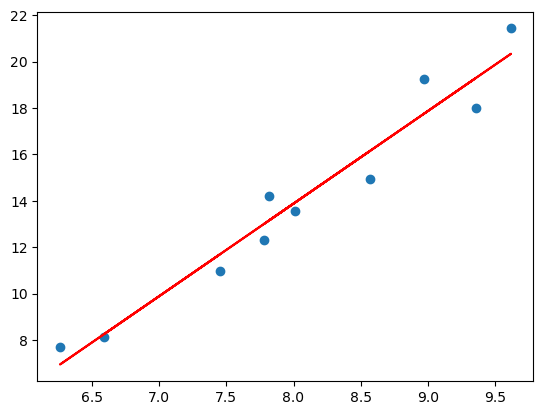

In [110]:
plt.scatter(x,y)
plt.plot(x,model.coef_*x+model.intercept_,color='r')

# Multiple Liner Regression

In [111]:
df=pd.read_csv(r'../../Datasets\Exp_Salaries.csv')
df.head()

,Salary,Years_Previous_Experience,Years Employed,Years_Education,Gender,Department,Number_Supervised
0,32782,1,0,7,Male,A,0
1,32920,3,15,9,Female,A,4
2,29548,6,5,1,Male,A,0
3,39828,6,18,5,Female,A,5
4,31528,11,3,3,Male,A,6


In [112]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46 entries, 0 to 45
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Salary                     46 non-null     int64 
 1   Years_Previous_Experience  46 non-null     int64 
 2   Years Employed             46 non-null     int64 
 3   Years_Education            46 non-null     int64 
 4   Gender                     46 non-null     object
 5   Department                 46 non-null     object
 6   Number_Supervised          46 non-null     int64 
dtypes: int64(5), object(2)
memory usage: 2.6+ KB


In [113]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import make_column_transformer,make_column_selector
from sklearn.metrics import r2_score
X,y=df.drop('Salary',axis=1), df['Salary']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3, random_state=26)

In [114]:
ohe=OneHotEncoder(sparse_output=False,drop='first').set_output(transform='pandas')
scaler=StandardScaler()
model=LinearRegression()
ct=make_column_transformer(
    (ohe,make_column_selector(dtype_include='object')),
    ('passthrough',make_column_selector(dtype_include='number')),
    verbose_feature_names_out=False
).set_output(transform='pandas')



In [115]:
pipe=Pipeline([('OHE',ct),('SLR',scaler),('LR',model)])
pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('OHE', ...), ('SLR', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Years_Previous_Experience','Years Employed','Years_Education','Gender', 'Department','Number_Supervised']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...), ('passthrough', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature

In [116]:
y_pred=pipe.predict(X_test)
r2_score(y_test,y_pred)

0.522925327646889

## polynomial Linear Regression 

In [117]:
from sklearn.preprocessing import PolynomialFeatures
poly=PolynomialFeatures(degree=2,include_bias=False)

In [118]:
pipe=Pipeline([('OHE',ct),('POLY',poly),('SLR',scaler),('LR',model)])
pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('OHE', ...), ('POLY', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Years_Previous_Experience','Years Employed','Years_Education','Gender', 'Department','Number_Supervised']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...), ('passthrough', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_featur

In [119]:
y_pred=pipe.predict(X_test)
r2_score(y_test,y_pred)

0.3416630642716473

### here the polynomial of degree 2 is not making any sense so lets try on diffrent degrees 

In [120]:
scores=[]
for i in range(2,6):
    poly=PolynomialFeatures(degree=i,include_bias=False)
    pipe=Pipeline([('OHE',ct),('POLY',poly),('SLR',scaler),('LR',model)])
    pipe.fit(X_train,y_train)
    y_pred=pipe.predict(X_test)
    scores.append([i,r2_score(y_test,y_pred)])
poly_scores=pd.DataFrame(scores,columns=['Degree','r2_score'])
poly_scores.sort_values(by='r2_score',ascending=False)

,Degree,r2_score
0,2,0.341663
1,3,-0.031102
2,4,-0.326891
3,5,-1.410647


## Lets try to applay on the Ridge Regression , scaling is very important because the penality is equal for all features

In [122]:
from sklearn.linear_model import Ridge
alphas=np.linspace(0.01,10,20)
for a in alphas:
    model = Ridge(alpha=a)
    pipe=Pipeline([('OHE',ct),('SLR',scaler),('RID',model)])
    pipe.fit(X_train,y_train)
    y_pred=pipe.predict(X_test)
    scores.append([a,r2_score(y_test,y_pred)])
poly_scores=pd.DataFrame(scores,columns=['alpha','r2_score'])
poly_scores.sort_values(by='r2_score',ascending=False).head()

,alpha,r2_score
37,6.845263,0.740076
17,6.845263,0.740076
36,6.319474,0.739938
16,6.319474,0.739938
18,7.371053,0.739837
